# Итоговая работа: кластеризация футболистов топ-5 лиг по стилю игры
# Выполнил студент ФМИ–ПМИ–1–2025 Азанов Егор Сергеевич.
**Данные:** статистика игроков сезона 2022/23 с FBref (Kaggle: `vivovinco/20222023-football-player-stats`) — 2689 строк, 124 столбца, почти все показатели посчитаны «на 90 минут».

**Задача:** не используя позиции, найти по статистике группы игроков с похожим стилем (роли), сравнить методы понижения размерности и кластеризации из курса и объяснить, что получилось. Позиции (DF/MF/FW) беру только для проверки в конце.

In [ ]:
%pip install -q umap-learn trimap pacmap phate kagglehub

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import time
import logging
import warnings
warnings.filterwarnings('ignore')  # чтобы не засоряли вывод
logging.getLogger('pacmap').setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.manifold import MDS, Isomap, LocallyLinearEmbedding, TSNE, trustworthiness
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, OPTICS, SpectralClustering, Birch
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.feature_selection import f_classif
from sklearn.metrics import (silhouette_score, calinski_harabasz_score, davies_bouldin_score,
                             adjusted_rand_score, adjusted_mutual_info_score, v_measure_score,
                             pairwise_distances)
from scipy.cluster.hierarchy import linkage, dendrogram
import umap, trimap, pacmap, phate

pd.set_option('display.max_columns', 50)
sns.set_style('whitegrid')
RS = 42  # random_state везде одинаковый, чтобы результаты повторялись

## 1. Загрузка данных
Качаю через kagglehub (публичный датасет, логин не нужен). В файле разделитель `;` и кодировка cp1252 — с utf-8 падает, с latin-1 ломаются буквы вроде š.

In [ ]:
import kagglehub
path = kagglehub.dataset_download('vivovinco/20222023-football-player-stats')
print(path)
df_raw = pd.read_csv(path + '/2022-2023 Football Player Stats.csv', sep=';', encoding='cp1252')
print(df_raw.shape)
df_raw.head()

Using Colab cache for faster access to the '20222023-football-player-stats' dataset.
/kaggle/input/20222023-football-player-stats
(2689, 124)


,Rk,Player,Nation,Pos,Squad,Comp,Age,Born,MP,Starts,Min,90s,Goals,Shots,SoT,SoT%,G/Sh,G/SoT,ShoDist,ShoFK,ShoPK,PKatt,PasTotCmp,PasTotAtt,PasTotCmp%,...,Carries,CarTotDist,CarPrgDist,CarProg,Car3rd,CPA,CarMis,CarDis,Rec,RecProg,CrdY,CrdR,2CrdY,Fls,Fld,Off,Crs,TklW,PKwon,PKcon,OG,Recov,AerWon,AerLost,AerWon%
0,1,Brenden Aaronson,USA,MFFW,Leeds United,Premier League,22,2000,20,19,1596,17.7,1,1.53,0.28,18.5,0.04,0.20,19.0,0.11,0.0,0.0,23.2,31.0,74.9,...,26.7,136.1,56.6,1.53,1.07,0.40,2.60,3.11,30.2,5.65,0.11,0.0,0.0,0.62,2.26,0.17,2.54,0.51,0.0,0.0,0.00,4.86,0.34,1.19,22.2
1,2,Yunis Abdelhamid,MAR,DF,Reims,Ligue 1,35,1987,22,22,1980,22.0,0,0.86,0.05,5.3,0.00,0.00,13.5,0.00,0.0,0.0,38.5,47.2,81.5,...,40.0,234.2,125.0,0.55,0.23,0.09,0.73,0.68,34.5,0.23,0.09,0.0,0.0,1.32,0.50,0.05,0.18,1.59,0.0,0.0,0.00,6.64,2.18,1.23,64.0
2,3,Himad Abdelli,FRA,MFFW,Angers,Ligue 1,23,1999,14,8,770,8.6,0,1.05,0.35,33.3,0.00,0.00,19.2,0.00,0.0,0.0,40.0,49.5,80.8,...,48.5,298.5,151.0,2.56,2.56,0.47,2.09,1.05,43.4,5.93,0.12,0.0,0.0,1.74,1.28,0.00,1.05,1.40,0.0,0.0,0.00,8.14,0.93,1.05,47.1
3,4,Salis Abdul Samed,GHA,MF,Lens,Ligue 1,22,2000,20,20,1799,20.0,1,0.60,0.15,25.0,0.08,0.33,20.3,0.00,0.0,0.0,59.5,64.9,91.6,...,61.0,316.9,117.5,1.25,1.95,0.15,1.35,1.30,56.5,1.70,0.15,0.0,0.0,2.45,1.35,0.00,0.35,0.80,0.0,0.0,0.05,6.60,0.50,0.50,50.0
4,5,Laurent Abergel,FRA,MF,Lorient,Ligue 1,30,1993,15,15,1165,12.9,0,0.31,0.00,0.0,0.00,0.00,23.9,0.00,0.0,0.0,37.9,43.4,87.3,...,41.0,174.3,72.7,0.47,0.93,0.00,1.32,0.78,36.4,0.47,0.16,0.0,0.0,0.93,1.01,0.00,0.23,2.02,0.0,0.0,0.00,6.51,0.31,0.39,44.4


## 2. Первичный анализ
Почти все показатели «на 90 минут». Исключения: Goals (сумма за сезон), MP, Starts, Min.

In [ ]:
print(df_raw.dtypes.value_counts())
print('пропуски:', df_raw.isna().sum().sum())
print(df_raw[df_raw.isna().any(axis=1)][['Player', 'Nation']])
print('дублей по имени+году рождения:', df_raw.duplicated(['Player', 'Born']).sum())
df_raw[df_raw.duplicated(['Player', 'Born'], keep=False)].sort_values('Player')[['Player', 'Born', 'Squad', 'Min']].head(6)

float64    112
int64        7
object       5
Name: count, dtype: int64
пропуски: 1
          Player Nation
1875  David Ozoh    NaN
дублей по имени+году рождения: 151


,Player,Born,Squad,Min
1867,Adam Ounas,1996,Napoli,15
1868,Adam Ounas,1996,Lille,784
787,Adri Embarba,1992,Espanyol,35
786,Adri Embarba,1992,Almería,786
2427,Adrien Thomasson,1993,Strasbourg,937
2428,Adrien Thomasson,1993,Lens,129


пропуск один - у игрока не указана страна, нам не важно.
дубли - это зимние трансферы (игрок есть в двух клубах). два «Rodrigo» - разные люди (Лидс и Бетис)

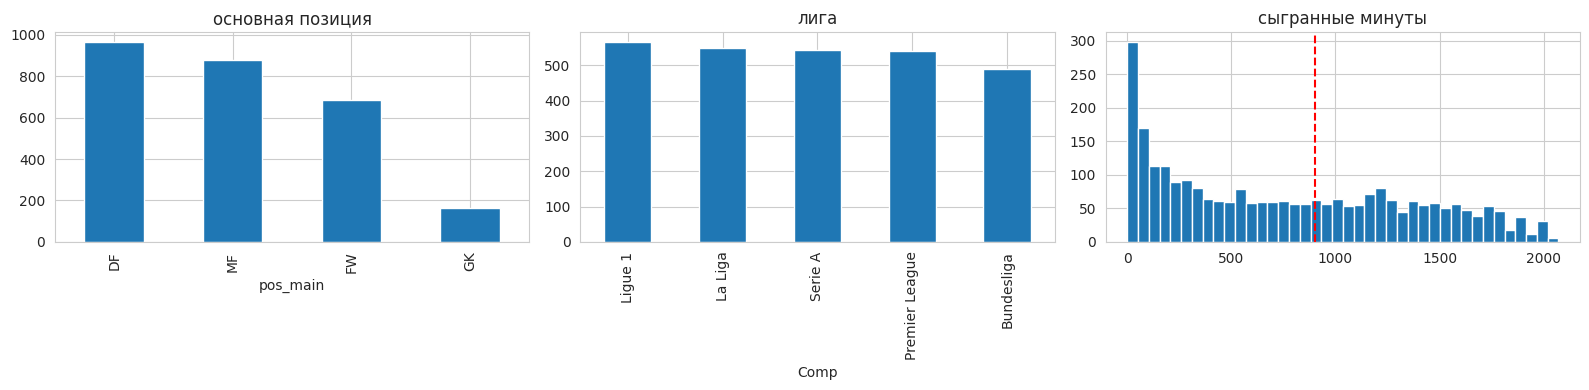

In [ ]:
df_raw['pos_main'] = df_raw['Pos'].str[:2]   #беру первую позицию

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
df_raw['pos_main'].value_counts().plot.bar(ax=ax[0], title='основная позиция')
df_raw['Comp'].value_counts().plot.bar(ax=ax[1], title='лига')
ax[2].hist(df_raw['Min'], bins=40)
ax[2].axvline(900, color='r', ls='--')
ax[2].set_title('сыгранные минуты')
plt.tight_layout()
plt.show()

много игроков с малым числом минут. у них статистика «на 90» случайная: 1 удар за 10 минут = 9 ударов за 90. беру тех, кто сыграл от 900 минут (10 полных матчей).
вратарей убираю - у них другая статистика (сейвы), они бы просто отделились в свой кластер.

## 3. Предобработка

In [ ]:
df = df_raw.sort_values('Min', ascending=False).drop_duplicates(['Player', 'Born'])  # оставляю клуб, где больше минут
df = df[(df['pos_main'] != 'GK') & (df['Min'] >= 900)].copy()
df = df.reset_index(drop=True)
df['Goals90'] = df['Goals'] / df['90s']    # пересчитал на 90 минут голы
print(df.shape)
print(df['pos_main'].value_counts())

(997, 126)
pos_main
DF    447
MF    329
FW    221
Name: count, dtype: int64


In [ ]:
# признаки по группам, выбирал по смыслу. без дублей вроде Tkl+Int (= Tkl + Int) и без процентов-«итого»
groups = {
    'удары': ['Goals90', 'Shots', 'SoT', 'ShoDist'],
    'пасы': ['PasTotAtt', 'PasTotCmp%', 'PasShoAtt', 'PasLonAtt', 'PasLonCmp%', 'PasProg', 'PPA', 'CrsPA', 'TB', 'Sw', 'PasCrs', 'Assists'],
    'созидание': ['SCA', 'GCA'],
    'оборона': ['Tkl', 'TklDef3rd', 'TklMid3rd', 'TklAtt3rd', 'TklDri%', 'Int', 'Blocks', 'Clr', 'Recov'],
    'владение': ['Touches', 'TouDefPen', 'TouAttPen', 'ToAtt', 'ToSuc%', 'Carries', 'CarProg', 'CPA', 'CarDis', 'RecProg'],
    'прочее': ['Fls', 'Fld', 'Off', 'AerWon', 'AerWon%'],
}
features = []
for g in groups.values():
    features += g
print(len(features), 'признаков')

X_raw = df[features]
print('пропусков в признаках:', X_raw.isna().sum().sum())
y_pos = df['pos_main'].map({'DF': 0, 'MF': 1, 'FW': 2}).values   # позиции - только для проверки
X_raw.describe().T[['mean', 'std', 'min', 'max']].round(2)

42 признаков
пропусков в признаках: 0


,mean,std,min,max
Goals90,0.14,0.18,0.00,1.37
Shots,1.21,0.93,0.00,5.55
SoT,0.41,0.41,0.00,2.27
ShoDist,17.51,5.31,0.00,37.90
PasTotAtt,46.09,15.71,11.60,104.20
PasTotCmp%,78.02,8.12,45.80,95.50
PasShoAtt,19.24,6.89,4.96,51.70
PasLonAtt,6.00,3.40,0.10,20.60
PasLonCmp%,58.03,12.76,23.60,100.00
PasProg,3.88,1.82,0.45,12.70


## 4. EDA
какие признаки сильнее всего отличаются между позициями (F-тест) и как признаки связаны между собой.

TouAttPen    753.3
Shots        674.4
SoT          624.0
Clr          604.5
Off          590.0
TouDefPen    516.5
Goals90      427.0
CarDis       415.7
dtype: float64


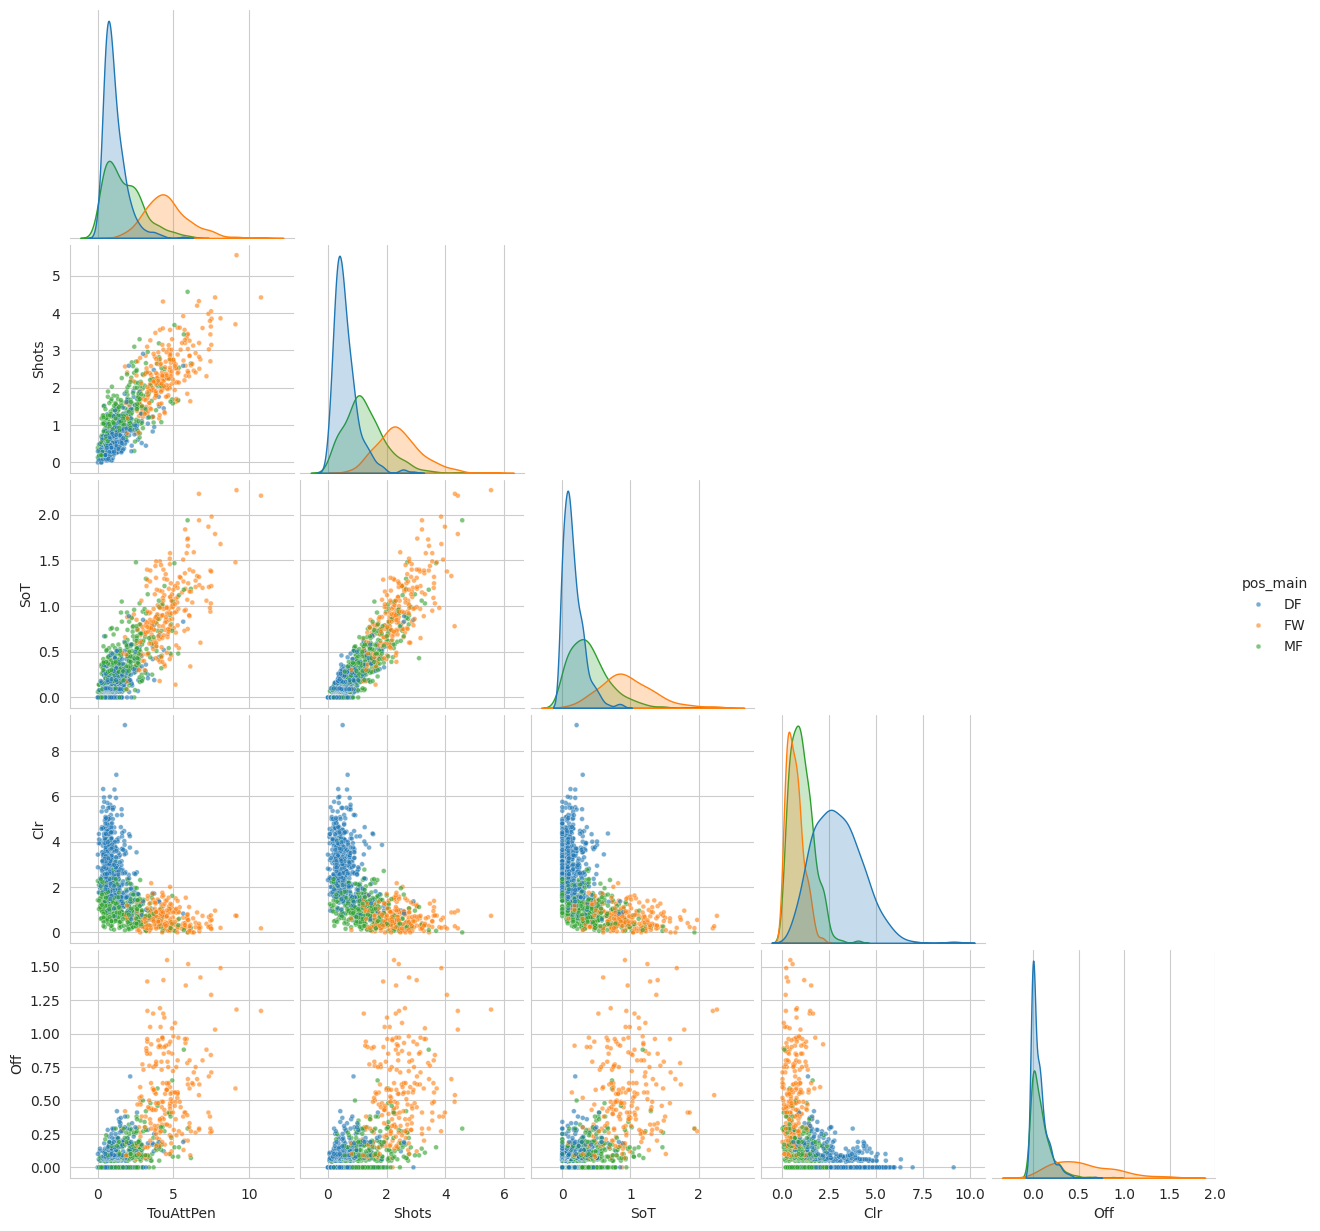

In [ ]:
F, _ = f_classif(X_raw, y_pos)
f_rank = pd.Series(F, index=features).sort_values(ascending=False)
print(f_rank.head(8).round(1))
top5 = list(f_rank.index[:5])
sns.pairplot(df[top5 + ['pos_main']], hue='pos_main', corner=True, plot_kws={'s': 12, 'alpha': 0.6})
plt.show()

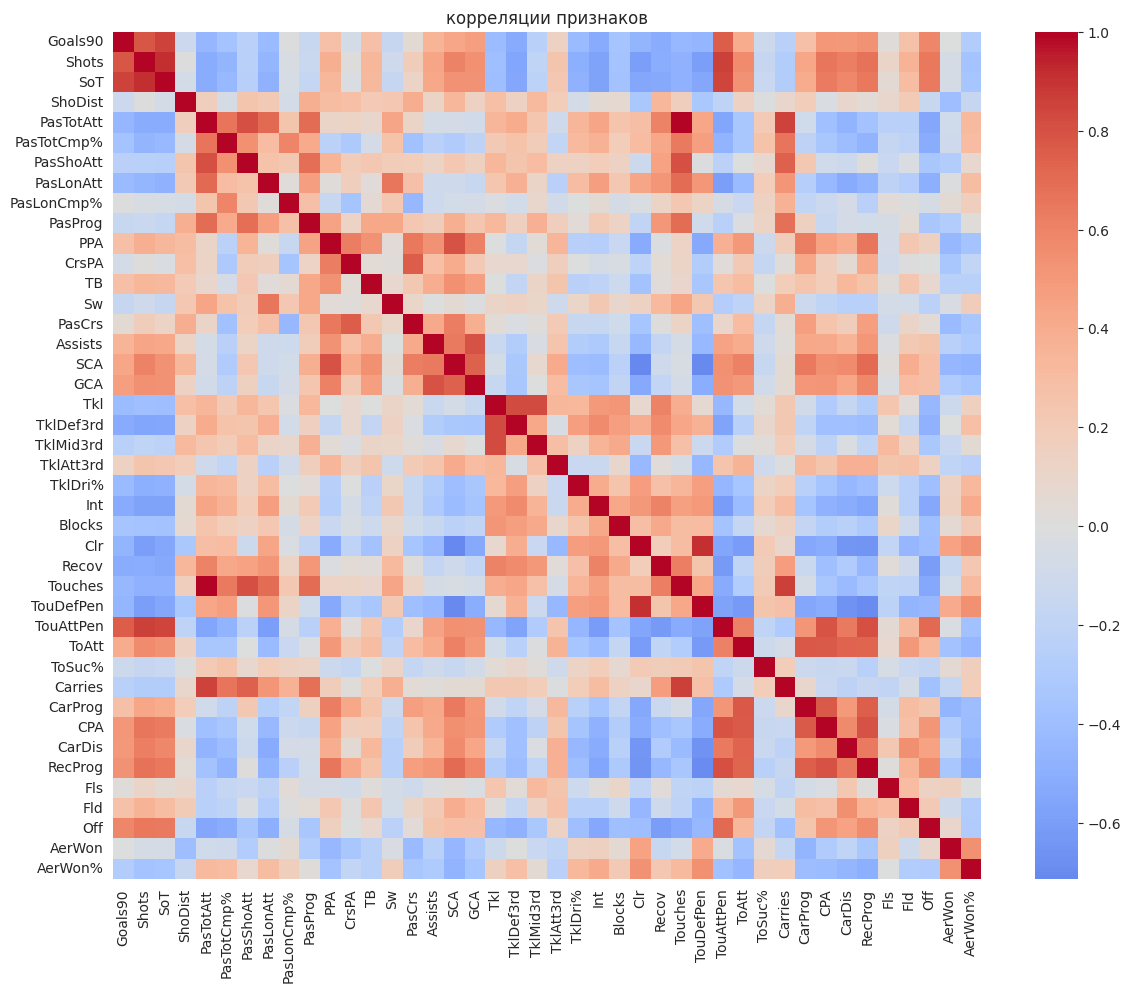

PasTotAtt  Touches      0.99
Shots      SoT          0.92
Clr        TouDefPen    0.91
Shots      TouAttPen    0.87
Touches    Carries      0.86
PasTotAtt  Carries      0.86
Goals90    SoT          0.85
SoT        TouAttPen    0.85
dtype: float64


In [ ]:
corr = X_raw.corr()
plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap='coolwarm', center=0, xticklabels=True, yticklabels=True)
plt.title('корреляции признаков')
plt.show()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
print(upper.stack().abs().sort_values(ascending=False).head(8).round(2))

признаки сильно связаны (касания/пасы/ведения, удары/удары в створ) -> данные избыточны, PCA должна хорошо сжать.

## 5. Масштабирование

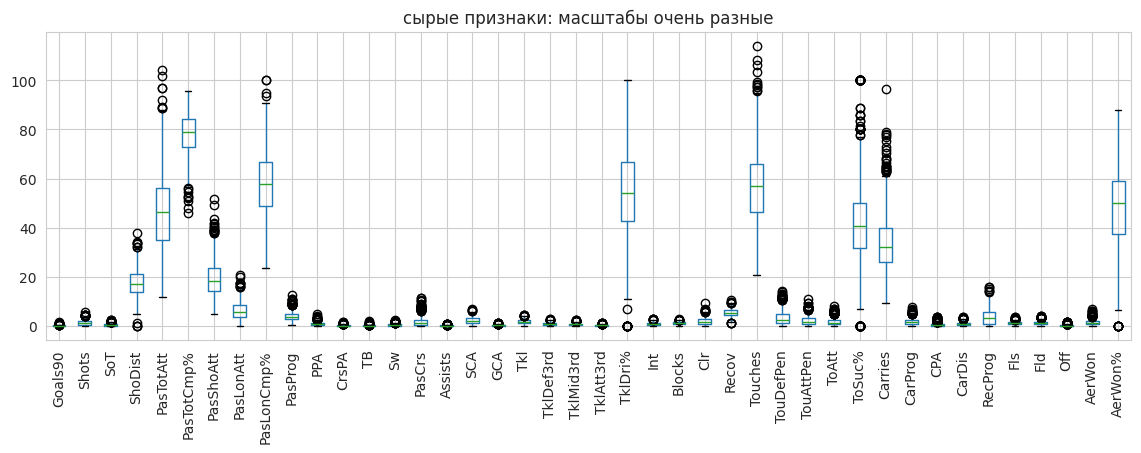

In [ ]:
plt.figure(figsize=(14, 4))
X_raw.boxplot(rot=90)
plt.title('сырые признаки: масштабы очень разные')
plt.show()

In [ ]:
# Проверка разных scaler-ов
for name, sc in [('без', None), ('Standard', StandardScaler()), ('MinMax', MinMaxScaler()), ('Robust', RobustScaler())]:
    Xt = X_raw.values if sc is None else sc.fit_transform(X_raw)
    lab = KMeans(3, n_init=10, random_state=RS).fit_predict(Xt)
    print(f'{name:9s} ARI с позициями = {adjusted_rand_score(y_pos, lab):.3f}')

без       ARI с позициями = 0.227
Standard  ARI с позициями = 0.383
MinMax    ARI с позициями = 0.373
Robust    ARI с позициями = 0.386


без масштабирования ARI 0.22 - всё решают признаки с большими числами (касаний и пасов ~50 за матч, голов ~0.1). Standard и Robust почти одинаково (0.38-0.39), беру StandardScaler.

In [ ]:
scaler = StandardScaler()
X = scaler.fit_transform(X_raw)   # дальше везде X - стандартизованные данные
print(X.shape, X.mean().round(3), X.std().round(3))

(997, 42) 0.0 1.0


## 6. PCA через SVD (ЛР2)
сначала руками через `np.linalg.svd`, потом сверяю со sklearn.

In [ ]:
Xc = X - X.mean(axis=0)                  # центрирование (после StandardScaler и так ~0)
U, S, VT = np.linalg.svd(Xc, full_matrices=False)    # экономное SVD
expl = S**2 / np.sum(S**2)               # доля дисперсии компоненты = sigma^2 / сумма sigma^2
pca_full = PCA().fit(X)
print('совпадает со sklearn:', np.allclose(expl, pca_full.explained_variance_ratio_))
cum = np.cumsum(expl)
n80 = np.argmax(cum >= 0.8) + 1
n90 = np.argmax(cum >= 0.9) + 1
print('компонент для 80%:', n80, ' для 90%:', n90)

совпадает со sklearn: True
компонент для 80%: 11  для 90%: 18


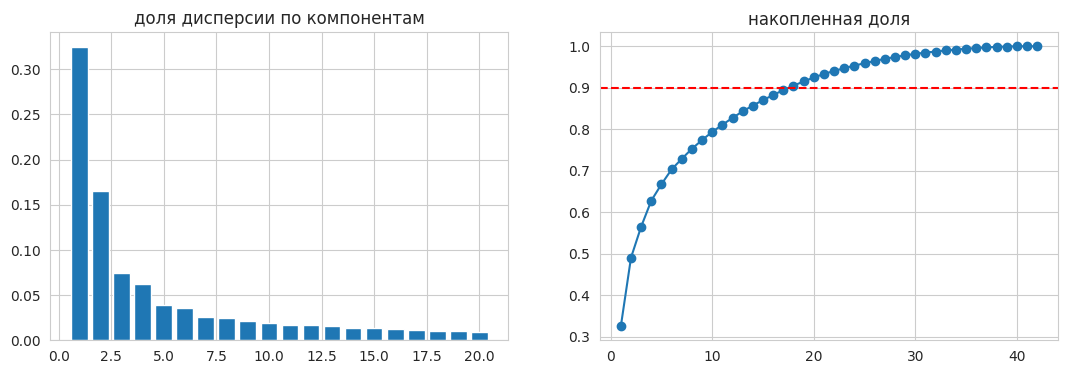

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(range(1, 21), expl[:20])
ax[0].set_title('доля дисперсии по компонентам')
ax[1].plot(range(1, len(cum) + 1), cum, 'o-')
ax[1].axhline(0.9, color='r', ls='--')
ax[1].set_title('накопленная доля')
plt.show()

In [ ]:
# Эккарт-Янг: ошибка восстановления по r компонентам = sqrt(сумма отброшенных sigma^2)
for r in [2, 5, n90]:
    Xr = U[:, :r] @ np.diag(S[:r]) @ VT[:r]
    print(r, 'ошибка:', round(np.linalg.norm(Xc - Xr), 2), ' формула:', round(np.sqrt(np.sum(S[r:]**2)), 2))

2 ошибка: 146.13  формула: 146.13
5 ошибка: 118.03  формула: 118.03
18 ошибка: 63.09  формула: 63.09


In [ ]:
loadings = pd.DataFrame(VT[:3].T, index=features, columns=['PC1', 'PC2', 'PC3'])
for pc in loadings.columns:
    s = loadings[pc].sort_values()
    print(pc, ' минус:', list(s.index[:4]), ' плюс:', list(s.index[-4:]))

PC1  минус: ['TouDefPen', 'Clr', 'Int', 'PasTotAtt']  плюс: ['SoT', 'Shots', 'RecProg', 'TouAttPen']
PC2  минус: ['PasProg', 'PasShoAtt', 'PPA', 'Touches']  плюс: ['TouDefPen', 'Off', 'Clr', 'AerWon']
PC3  минус: ['Carries', 'PasLonCmp%', 'PasTotCmp%', 'PasTotAtt']  плюс: ['TklDef3rd', 'Fls', 'TklMid3rd', 'Tkl']


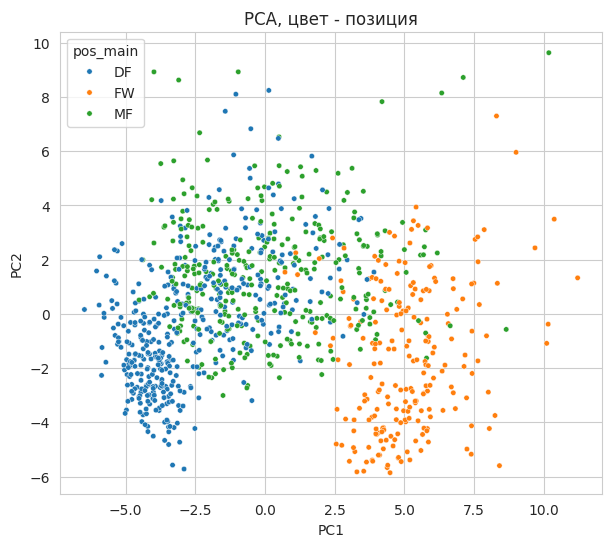

In [ ]:
X_pca = PCA(n_components=n90, random_state=RS).fit_transform(X)   # 90% дисперсии, тут дальше кластеризую
X_pca2 = X_pca[:, :2]
plt.figure(figsize=(7, 6))
sns.scatterplot(x=X_pca2[:, 0], y=X_pca2[:, 1], hue=df['pos_main'], s=15)
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.title('PCA, цвет - позиция')
plt.show()

- 80% дисперсии = 11 компонент, 90% = 18 из 42. SVD руками совпал со sklearn, ошибка восстановления совпала с формулой Эккарта-Янга.
- PC1: минус - касания в своей штрафной, выносы, перехваты; плюс - удары, касания в чужой штрафной. ось «защитник - нападающий».
- PC2: минус - пасы и продвижение мяча; плюс - выносы, офсайды, игра в воздухе. «участвует в розыгрыше или нет» (центрбеки и таргетмены с одной стороны).
- PC3: отборы против точных пасов и ведения - «разрушитель vs распасовщик».

на картинке позиции идут полосами вдоль PC1, полузащитники посередине и заходят на обе стороны.

## 7. Нелинейные методы (ЛР3, практика 7)
все в 2D на стандартизованных данных, замеряю время. trustworthiness - сохраняются ли соседи, ratio - насколько разведены позиции.

In [ ]:
np.random.seed(RS)   # у TriMAP нет random_state
methods = {
    'MDS': MDS(n_components=2, n_init=1, max_iter=300, random_state=RS),
    'Isomap': Isomap(n_components=2, n_neighbors=15),
    'LLE': LocallyLinearEmbedding(n_components=2, n_neighbors=50, method='standard', random_state=RS),
    't-SNE': TSNE(n_components=2, perplexity=30, init='pca', random_state=RS),
    'UMAP': umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=RS),
    'TriMAP': trimap.TRIMAP(n_dims=2),
    'PaCMAP': pacmap.PaCMAP(n_components=2, n_neighbors=10, random_state=RS),
    'PHATE': phate.PHATE(n_components=2, knn=15, random_state=RS, verbose=0),
}
emb = {'PCA': X_pca2}
times = {'PCA': 0.0}
for name, model in methods.items():
    t0 = time.time()
    emb[name] = model.fit_transform(X)
    times[name] = time.time() - t0
    print(f'{name:7s} {times[name]:.1f} c')

MDS     10.1 c
Isomap  0.4 c
LLE     0.4 c
t-SNE   9.0 c
UMAP    19.2 c
TriMAP  1.4 c
PaCMAP  0.6 c
PHATE   12.8 c


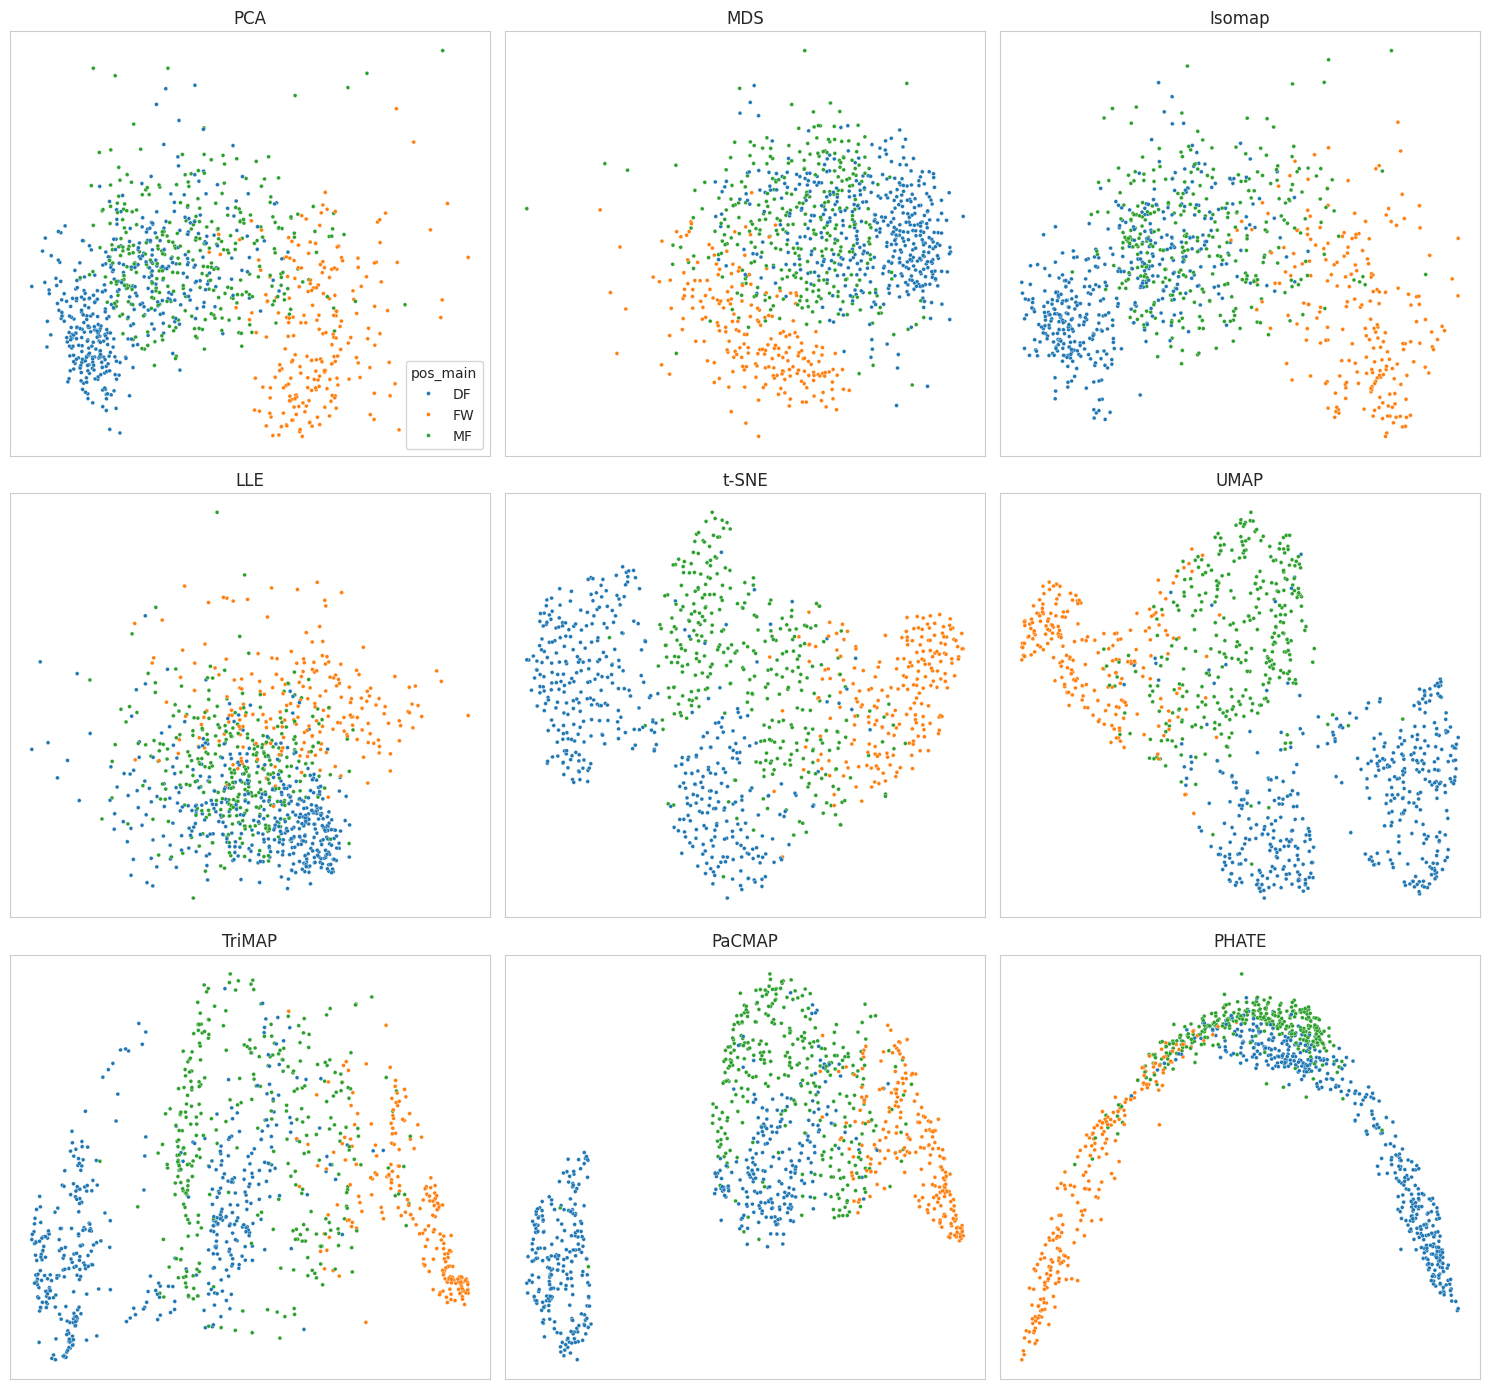

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(15, 14))
for ax, (name, E) in zip(axes.flat, emb.items()):
    sns.scatterplot(x=E[:, 0], y=E[:, 1], hue=df['pos_main'], s=8, ax=ax, legend=(name == 'PCA'))
    ax.set_title(name)
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

In [ ]:
def sep_ratio(E, y):
    D = pairwise_distances(E)
    same = y[:, None] == y[None, :]
    return D[~same].mean() / D[same].mean()

rows = []
for name, E in emb.items():
    rows.append({'метод': name, 'trust': trustworthiness(X, E, n_neighbors=10),
                 'ratio': sep_ratio(E, y_pos), 'время, с': times[name]})
dr_table = pd.DataFrame(rows).set_index('метод').round(3)
dr_table

,trust,ratio,"время, с"
метод,,,
PCA,0.880,1.666,0.000
MDS,0.877,1.515,10.062
Isomap,0.877,1.814,0.443
LLE,0.771,1.330,0.405
t-SNE,0.956,1.852,8.953
UMAP,0.937,2.103,19.185
TriMAP,0.926,1.913,1.394
PaCMAP,0.920,1.746,0.559
PHATE,0.869,2.020,12.764


- соседей лучше всех сохраняет t-SNE (trust ~0.96), потом UMAP (~0.94), TriMAP и PaCMAP (~0.92). PCA, MDS, Isomap ~0.87-0.88.
- LLE капризный на реальных данных: modified с k=20 схлопывался в «иглу» с выбросами (как в ЛР3). standard с k=50 тоже сжал почти всех в узкий клин + пара выбросов, trust самый низкий (~0.77). общую картину LLE тут не показывает.
- позиции сильнее всего разводят PHATE, TriMAP и UMAP (ratio ~2.0).
- быстрые LLE, PaCMAP, Isomap, TriMAP (доли секунды), дольше всех UMAP (~5 с, однопоточный из-за random_state).
- главное: отдельно стоит только группа защитников (полоса слева на TriMAP и PaCMAP, «остров» сверху на UMAP; ниже DBSCAN покажет, что это центральные защитники). остальные игроки - сплошной от защитников к нападающим. чётких кластеров почти нет, силуэт будет низкий.

## 8. Сколько кластеров
кластеризую в PCA-пространстве (90% дисперсии). критерии из ЛР1 + устойчивость из практики 8.

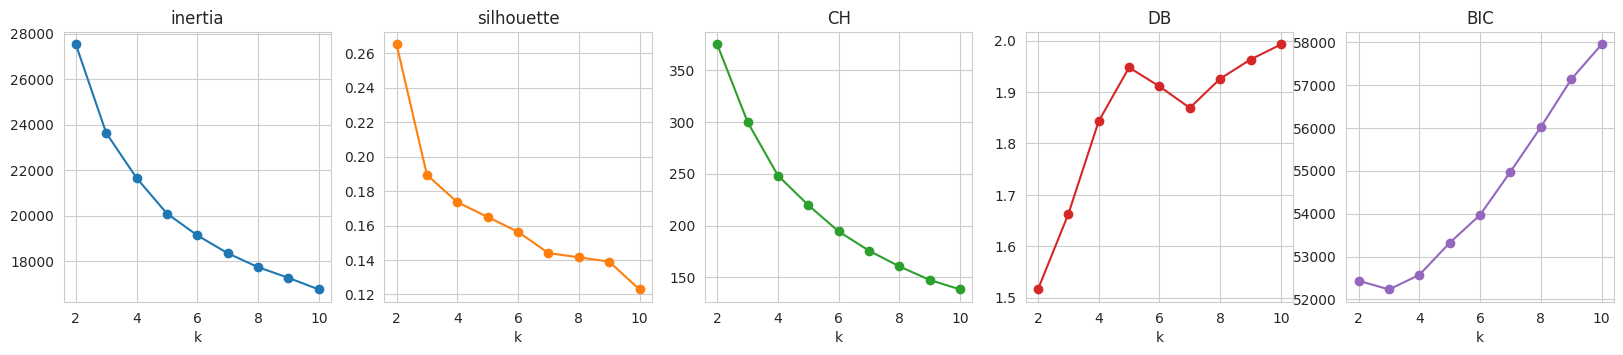

,inertia,silhouette,CH,DB,BIC
k,,,,,
2,27524.150,0.265,374.855,1.516,52437.359
3,23632.906,0.189,299.901,1.663,52233.091
4,21653.461,0.174,248.250,1.843,52573.890
5,20093.485,0.165,219.694,1.948,53321.967
6,19135.367,0.156,194.293,1.911,53972.556
7,18351.115,0.144,175.712,1.869,54978.991
8,17737.760,0.142,160.546,1.926,56020.091
9,17269.324,0.139,147.492,1.963,57134.346
10,16757.671,0.123,138.319,1.993,57947.065


In [ ]:
res = []
for k in range(2, 11):
    km = KMeans(k, n_init=10, random_state=RS).fit(X_pca)
    gm = GaussianMixture(k, random_state=RS).fit(X_pca)
    res.append({'k': k, 'inertia': km.inertia_,
                'silhouette': silhouette_score(X_pca, km.labels_),
                'CH': calinski_harabasz_score(X_pca, km.labels_),
                'DB': davies_bouldin_score(X_pca, km.labels_),
                'BIC': gm.bic(X_pca)})
k_table = pd.DataFrame(res).set_index('k')
k_table.plot(subplots=True, layout=(1, 5), figsize=(20, 3.5), marker='o', legend=False, title=list(k_table.columns))
plt.show()
k_table.round(3)

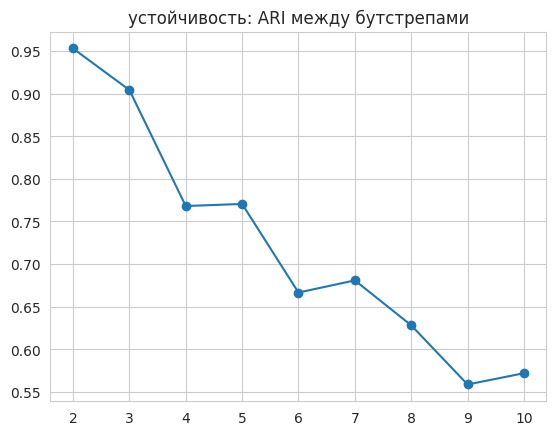

2     0.953
3     0.904
4     0.768
5     0.770
6     0.666
7     0.681
8     0.628
9     0.559
10    0.572
dtype: float64


In [ ]:
# устойчивость: две бутстреп-выборки, кластеризую каждую и сравниваю разметку всех игроков
rng = np.random.RandomState(0)
stab = {}
for k in range(2, 11):
    scores = []
    for b in range(20):
        i1 = rng.choice(len(X_pca), len(X_pca))
        i2 = rng.choice(len(X_pca), len(X_pca))
        m1 = KMeans(k, n_init=5, random_state=b).fit(X_pca[i1])
        m2 = KMeans(k, n_init=5, random_state=b + 100).fit(X_pca[i2])
        scores.append(adjusted_rand_score(m1.predict(X_pca), m2.predict(X_pca)))
    stab[k] = np.mean(scores)
pd.Series(stab).plot(marker='o', title='устойчивость: ARI между бутстрепами')
plt.show()
print(pd.Series(stab).round(3))

- силуэт, CH и DB лучше всего при k=2, BIC при k=3. по геометрии данные делятся на «защитников» и «атакующих» - это и так понятно.
- устойчивость падает с ростом k: 0.95 при k=2 -> 0.66 при k=6 -> 0.57 при k=10.
- беру k=6: роли получаются осмысленные (раздел 12), устойчивость 0.66 ещё нормальная, дальше падает. компромисс между метриками и смыслом.
- низкий силуэт (0.15) - не ошибка, стили игроков перетекают друг в друга.

In [ ]:
K = 6

## 9. Кластеризация: 7 алгоритмов на PCA-пространстве
eps для DBSCAN - по колену графика расстояний до 10-го соседа (как в ЛР1).

In [ ]:
def knee_eps(Z, k=10):
    d = NearestNeighbors(n_neighbors=k).fit(Z).kneighbors(Z)[0][:, -1]
    d = np.sort(d)
    line = d[0] + (d[-1] - d[0]) * np.arange(len(d)) / (len(d) - 1)
    return d[np.argmax(line - d)]

eps = knee_eps(X_pca)
print('eps =', round(eps, 2))

algos = {
    'KMeans': KMeans(K, n_init=20, random_state=RS),
    'Ward': AgglomerativeClustering(K, linkage='ward'),
    'GMM': GaussianMixture(K, n_init=5, random_state=RS),
    'DBSCAN': DBSCAN(eps=eps, min_samples=10),
    'OPTICS': OPTICS(min_samples=10, min_cluster_size=0.03),
    'Spectral': SpectralClustering(K, affinity='nearest_neighbors', n_neighbors=15, random_state=RS),
    'BIRCH': Birch(n_clusters=K),
}
labels = {}
for name, model in algos.items():
    labels[name] = model.fit_predict(X_pca)
    n_cl = len(set(labels[name]) - {-1})
    print(f'{name:8s} кластеров: {n_cl}, шум: {(labels[name] == -1).mean():.0%}')

eps = 5.46
KMeans   кластеров: 6, шум: 0%
Ward     кластеров: 6, шум: 0%
GMM      кластеров: 6, шум: 0%
DBSCAN   кластеров: 1, шум: 2%
OPTICS   кластеров: 1, шум: 0%
Spectral кластеров: 6, шум: 0%
BIRCH    кластеров: 6, шум: 0%


In [ ]:
def evaluate(Z, lab, y=y_pos):
    m = lab != -1   # шум в внутренних метриках не учитываю
    out = {'кластеров': len(set(lab[m])), 'шум %': round(100 * (1 - m.mean()), 1)}
    if out['кластеров'] >= 2:
        out['silhouette'] = silhouette_score(Z[m], lab[m])
        out['CH'] = calinski_harabasz_score(Z[m], lab[m])
        out['DB'] = davies_bouldin_score(Z[m], lab[m])
    out['ARI'] = adjusted_rand_score(y, lab)
    out['AMI'] = adjusted_mutual_info_score(y, lab)
    out['V'] = v_measure_score(y, lab)
    return out

algo_table = pd.DataFrame({n: evaluate(X_pca, l) for n, l in labels.items()}).T
algo_table.round(3)

,кластеров,шум %,silhouette,CH,DB,ARI,AMI,V
KMeans,6.0,0.0,0.156,194.293,1.911,0.272,0.378,0.380
Ward,6.0,0.0,0.133,167.809,2.112,0.289,0.407,0.410
GMM,6.0,0.0,0.103,163.689,2.324,0.230,0.348,0.350
DBSCAN,1.0,1.7,NaN,NaN,NaN,0.003,-0.000,0.002
OPTICS,1.0,0.0,NaN,NaN,NaN,0.000,0.000,0.000
Spectral,6.0,0.0,0.114,170.665,2.120,0.362,0.492,0.494
BIRCH,6.0,0.0,0.133,167.809,2.112,0.289,0.407,0.410


- KMeans, Ward, GMM, Spectral и BIRCH дали по 6 кластеров. BIRCH совпал с Ward один в один (внутри он тоже объединяет иерархически).
- лучший силуэт у KMeans (0.155), лучшее совпадение с позициями у Spectral (ARI 0.36).
- DBSCAN и OPTICS в 18-мерном пространстве - один кластер: проклятие размерности, плотность везде примерно одинаковая.
- ARI с позициями небольшой (0.26-0.36) и не должен быть большим: позиций 3, а ролей 6, одна позиция делится на несколько ролей.

In [ ]:
# DBSCAN на UMAP (как в ЛР1): min_dist=0, чтобы точки сжимались в плотные группы
E0 = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.0, random_state=RS).fit_transform(X)
eps_u = knee_eps(E0, 20)
lab_db = DBSCAN(eps=eps_u, min_samples=20).fit_predict(E0)
labels['DBSCAN (UMAP)'] = lab_db
print('eps =', round(eps_u, 3))
print(pd.Series(evaluate(X_pca, lab_db)).round(3))
pd.crosstab(lab_db, df['pos_main'])

eps = 0.49
кластеров       2.000
шум %           2.500
silhouette      0.170
CH            222.594
DB              1.528
ARI             0.113
AMI             0.280
V               0.282
dtype: float64


pos_main,DF,FW,MF
row_0,,,
-1,20,2,3
0,232,0,1
1,195,219,325


на UMAP DBSCAN нашёл 3 группы + ~3% шума: центральные защитники / крайние защитники / все остальные (полузащитники и нападающие одним облаком). т.е. по плотности отделяются только защитники, а 6 ролей - это деление сплошного облака.

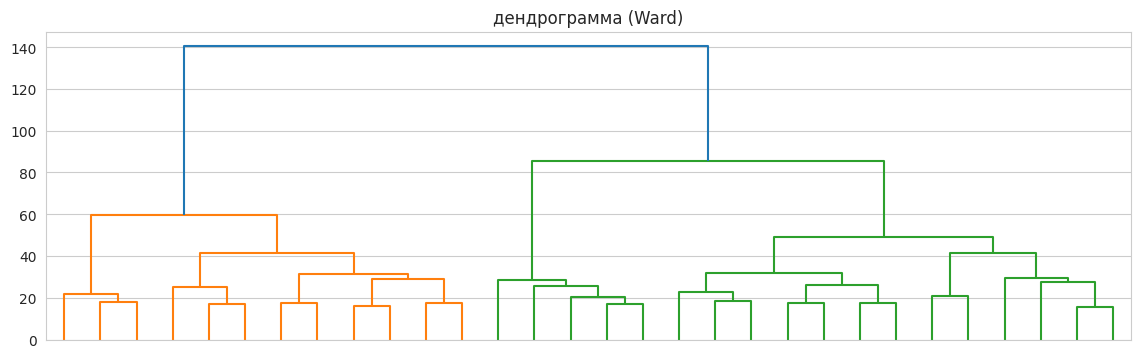

In [ ]:
Zl = linkage(X_pca, method='ward')
plt.figure(figsize=(14, 4))
dendrogram(Zl, truncate_mode='lastp', p=30, no_labels=True)
plt.title('дендрограмма (Ward)')
plt.show()

## 10. KMeans в разных пространствах (практика 8)
силуэт в «своём» пространстве нечестно сравнивать (t-SNE/UMAP сами сжимают кластеры), поэтому считаю ещё силуэт в общем - исходных 42 признаках.

In [ ]:
spaces = {'исходные 42': X, f'PCA {n90}': X_pca, 'Isomap': emb['Isomap'], 't-SNE': emb['t-SNE'],
          'UMAP': emb['UMAP'], 'PaCMAP': emb['PaCMAP']}
rows = []
for name, Z in spaces.items():
    lab = KMeans(K, n_init=10, random_state=RS).fit_predict(Z)
    rows.append({'пространство': name,
                 'sil (своё)': silhouette_score(Z, lab),
                 'sil (общее)': silhouette_score(X, lab),
                 'ARI позиции': adjusted_rand_score(y_pos, lab),
                 'ARI с PCA-KMeans': adjusted_rand_score(labels['KMeans'], lab)})
space_table = pd.DataFrame(rows).set_index('пространство')

def norm01(s):
    return (s - s.min()) / (s.max() - s.min())

space_table['score'] = 0.5 * norm01(space_table['sil (общее)']) + 0.5 * norm01(space_table['ARI позиции'])
space_table.sort_values('score', ascending=False).round(3)

,sil (своё),sil (общее),ARI позиции,ARI с PCA-KMeans,score
пространство,,,,,
UMAP,0.511,0.130,0.430,0.522,0.895
t-SNE,0.451,0.120,0.367,0.518,0.524
PCA 18,0.156,0.135,0.272,1.000,0.500
исходные 42,0.134,0.134,0.272,0.946,0.474
PaCMAP,0.507,0.108,0.325,0.601,0.167
Isomap,0.405,0.108,0.279,0.563,0.025


- силуэт в «своём» пространстве у UMAP, PaCMAP, t-SNE 0.42-0.51, а в общем у всех ~0.11-0.14. высокий силуэт делает сам метод (как в практике 8).
- по честному силуэту лучшие - исходные признаки и PCA.
- KMeans на UMAP сильнее всех совпадает с позициями (ARI ~0.41) и первый по комбинированной оценке.
- PCA и исходные 42 признака дают почти одно и то же разбиение (ARI ~0.86) - сжатие 42 -> 18 почти ничего не потеряло.
- итоговой оставляю KMeans на PCA: проще, есть transform для новых игроков, роли читаются.

## 11. Устойчивость итоговой модели (KMeans, k=6, PCA)

In [ ]:
seed_lab = [KMeans(K, n_init=1, random_state=s).fit_predict(X_pca) for s in range(10)]
seed_ari = [adjusted_rand_score(seed_lab[0], l) for l in seed_lab[1:]]
print('ARI между запусками (n_init=1):', np.round(seed_ari, 2))

boot = []
for b in range(50):
    idx = rng.choice(len(X_pca), len(X_pca))
    km = KMeans(K, n_init=5, random_state=b).fit(X_pca[idx])
    boot.append({'silhouette': silhouette_score(X_pca[idx], km.labels_),
                 'ARI позиции': adjusted_rand_score(y_pos[idx], km.labels_),
                 'ARI с полной моделью': adjusted_rand_score(labels['KMeans'], km.predict(X_pca))})
boot = pd.DataFrame(boot)
print(boot.agg(['mean', 'std']).round(3))
print(boot.quantile([0.025, 0.975]).round(3))

ARI между запусками (n_init=1): [0.62 0.63 0.62 0.58 0.62 0.79 0.55 0.66 0.84]
      silhouette  ARI позиции  ARI с полной моделью
mean       0.162        0.287                 0.718
std        0.007        0.027                 0.111
       silhouette  ARI позиции  ARI с полной моделью
0.025       0.151        0.258                 0.574
0.975       0.177        0.371                 0.906


- с одним стартом (n_init=1) KMeans нестабилен: ARI между запусками от 0.56 до 0.93. поэтому в итоговой модели n_init=20.
- бутстреп: модели на случайных выборках размечают игроков похоже на полную модель (ARI ~0.69, 95% интервал ~0.56-0.86), силуэт стабилен (0.15-0.18).

## 12. Что за кластеры (роли)
профиль = средние z-оценки признаков в кластере (0 = как средний игрок).

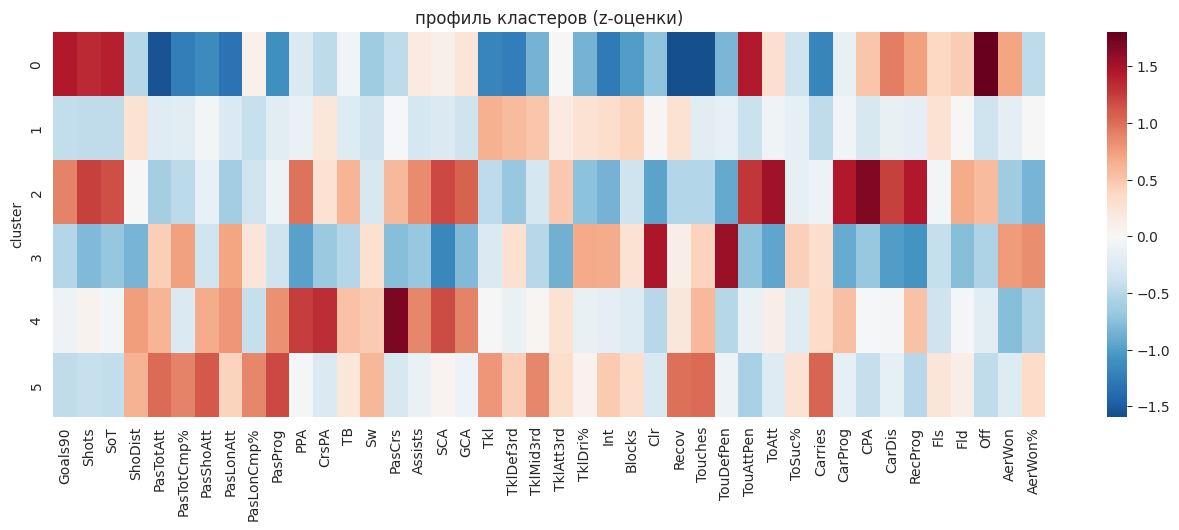

кластер 0 (127): выше всего ['Off', 'Goals90', 'TouAttPen', 'SoT'], ниже ['PasTotAtt', 'Touches', 'Recov']
    Harry Kane, Alexandre Lacazette, Brennan Johnson, Ivan Toney, Jonathan David, Karim Onisiwo
кластер 1 (235): выше всего ['Tkl', 'TklDef3rd', 'TklMid3rd', 'Blocks'], ниже ['Shots', 'Carries', 'SoT']
    Vincent Le Goff, Birama Touré, João Palhinha, Sergio Akieme, Rico Henry, Timothy Castagne
кластер 2 (138): выше всего ['CPA', 'ToAtt', 'CarProg', 'RecProg'], ниже ['Int', 'TouDefPen', 'Clr']
    Jarrod Bowen, Nikola Vlaši?, Miguel Almirón, Solly March, Bukayo Saka, Marcus Rashford
кластер 3 (221): выше всего ['TouDefPen', 'Clr', 'AerWon%', 'AerWon'], ниже ['CarDis', 'RecProg', 'SCA']
    Mateusz Wieteska, Tim Ream, Axel Disasi, Dante, Federico Baschirotto, Montassar Talbi
кластер 4 (119): выше всего ['PasCrs', 'CrsPA', 'PPA', 'SCA'], ниже ['TouDefPen', 'AerWon%', 'AerWon']
    James Ward-Prowse, Kieran Trippier, Enzo Le Fée, Branco van den Boomen, Andreas Pereira, Bruno Fernande

In [ ]:
df['cluster'] = labels['KMeans']
profile = pd.DataFrame(X, columns=features).groupby(df['cluster']).mean()
plt.figure(figsize=(16, 5))
sns.heatmap(profile, cmap='RdBu_r', center=0)
plt.title('профиль кластеров (z-оценки)')
plt.show()
for c in profile.index:
    top = profile.loc[c].sort_values(ascending=False)
    names = df[df['cluster'] == c].sort_values('Min', ascending=False)['Player'].head(6).tolist()
    print(f'кластер {c} ({(df.cluster == c).sum()}): выше всего {list(top.index[:4])}, ниже {list(top.index[-3:])}')
    print('   ', ', '.join(names))

In [ ]:
# называю кластеры по правилам, а не руками: номера кластеров могут поменяться при другой версии sklearn
rules = [('Clr', 'центральные защитники'), ('Goals90', 'нападающие-финишёры'), ('CPA', 'вингеры-дриблёры'),
         ('PasCrs', 'подающие-креативщики'), ('PasTotAtt', 'опорники-распасовщики'), ('Tkl', 'отборщики')]
role = {}
left = list(profile.index)
for feat, name in rules:
    c = profile.loc[left, feat].idxmax()
    role[c] = name
    left.remove(c)
df['role'] = df['cluster'].map(role)
print(pd.crosstab(df['role'], df['pos_main']))
pd.crosstab(df['role'], df['Comp'], normalize='columns').round(2)

pos_main                DF   FW   MF
role                                
вингеры-дриблёры         7   87   44
нападающие-финишёры      0  124    3
опорники-распасовщики   46    0  111
отборщики              122    4  109
подающие-креативщики    55    6   58
центральные защитники  217    0    4


Comp,Bundesliga,La Liga,Ligue 1,Premier League,Serie A
role,,,,,
вингеры-дриблёры,0.11,0.15,0.12,0.17,0.13
нападающие-финишёры,0.14,0.12,0.14,0.10,0.14
опорники-распасовщики,0.09,0.19,0.23,0.15,0.12
отборщики,0.30,0.20,0.21,0.24,0.25
подающие-креативщики,0.13,0.12,0.10,0.11,0.14
центральные защитники,0.23,0.22,0.21,0.23,0.22


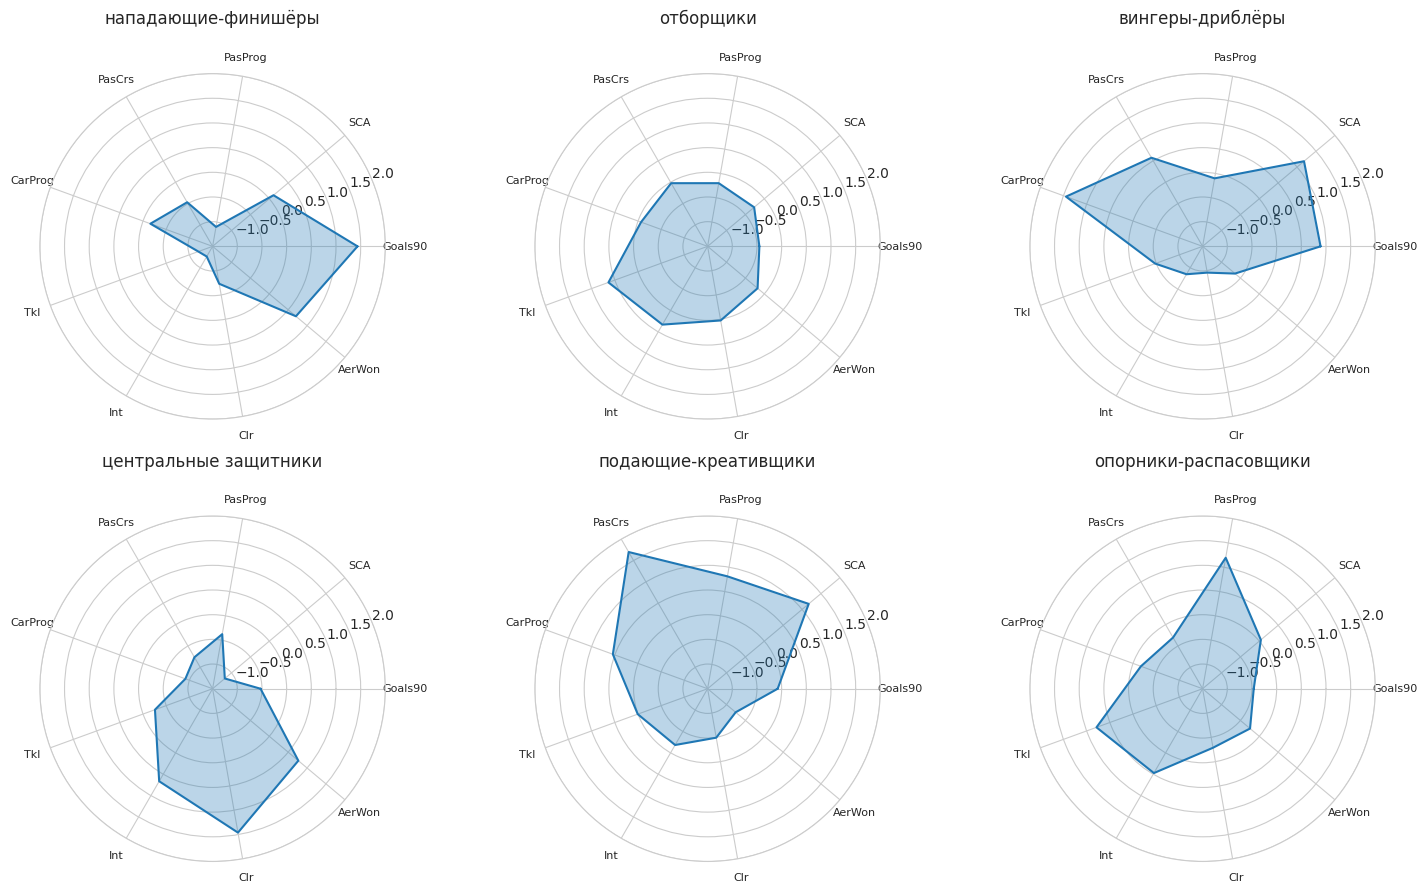

In [ ]:
radar = ['Goals90', 'SCA', 'PasProg', 'PasCrs', 'CarProg', 'Tkl', 'Int', 'Clr', 'AerWon']
angles = np.linspace(0, 2 * np.pi, len(radar), endpoint=False)
angles = np.append(angles, angles[0])
fig = plt.figure(figsize=(15, 9))
for i, c in enumerate(profile.index):
    ax = fig.add_subplot(2, 3, i + 1, polar=True)
    vals = np.append(profile.loc[c, radar].values, profile.loc[c, radar[0]])
    ax.plot(angles, vals)
    ax.fill(angles, vals, alpha=0.3)
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(radar, fontsize=8)
    ax.set_ylim(-1.5, 2)
    ax.set_title(role[c], y=1.12)
plt.tight_layout()
plt.show()

In [ ]:
stars = ['Erling Haaland', 'Kylian Mbappé', 'Lionel Messi', 'Kevin De Bruyne', 'Rodri', 'Joshua Kimmich',
         'Bukayo Saka', 'Virgil van Dijk', 'Jude Bellingham', 'Mohamed Salah', 'Kieran Trippier', 'João Palhinha']
df[df['Player'].isin(stars)][['Player', 'Squad', 'pos_main', 'role']]

,Player,Squad,pos_main,role
21,João Palhinha,Fulham,MF,отборщики
22,Kieran Trippier,Newcastle Utd,DF,подающие-креативщики
67,Bukayo Saka,Arsenal,FW,вингеры-дриблёры
90,Mohamed Salah,Liverpool,FW,вингеры-дриблёры
117,Rodri,Manchester City,MF,опорники-распасовщики
151,Jude Bellingham,Dortmund,MF,опорники-распасовщики
197,Erling Haaland,Manchester City,FW,нападающие-финишёры
223,Kevin De Bruyne,Manchester City,MF,подающие-креативщики
226,Joshua Kimmich,Bayern Munich,MF,подающие-креативщики
247,Lionel Messi,Paris S-G,MF,вингеры-дриблёры


In [ ]:
def similar(name, n=5):
    i = df.index[df['Player'] == name][0]
    nn = NearestNeighbors(n_neighbors=n + 1).fit(X_pca)
    idx = nn.kneighbors(X_pca[i:i + 1])[1][0][1:]
    return df.loc[idx, ['Player', 'Squad', 'role']]

similar('Lionel Messi')

,Player,Squad,role
327,Neymar,Paris S-G,вингеры-дриблёры
223,Kevin De Bruyne,Manchester City,подающие-креативщики
778,Ousmane Dembélé,Barcelona,вингеры-дриблёры
156,Martin Ødegaard,Arsenal,вингеры-дриблёры
657,Rémy Cabella,Lille,подающие-креативщики


In [ ]:
similar('Rodri')

,Player,Squad,role
20,Pierre Højbjerg,Tottenham,опорники-распасовщики
312,Jordan Veretout,Marseille,опорники-распасовщики
811,Aurélien Tchouaméni,Real Madrid,опорники-распасовщики
967,Corentin Tolisso,Lyon,опорники-распасовщики
951,Fabián Ruiz Peña,Paris S-G,опорники-распасовщики


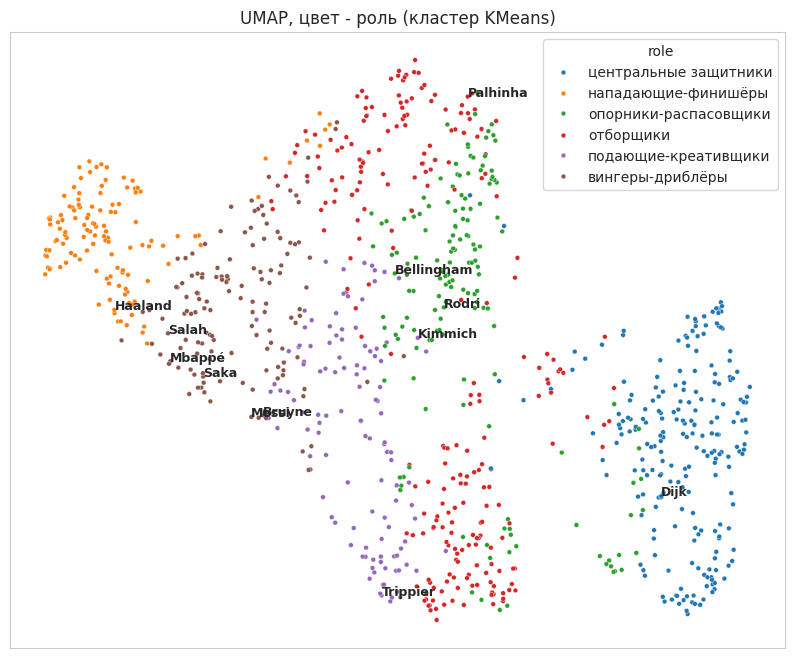

In [ ]:
E2 = emb['UMAP']
plt.figure(figsize=(10, 8))
sns.scatterplot(x=E2[:, 0], y=E2[:, 1], hue=df['role'], s=12, palette='tab10')
for name in stars:
    m = df['Player'] == name
    if m.any():
        plt.annotate(name.split()[-1], E2[m.values][0], fontsize=9, weight='bold')
plt.title('UMAP, цвет - роль (кластер KMeans)')
plt.xticks([]); plt.yticks([])
plt.show()

In [ ]:
E3 = umap.UMAP(n_components=3, n_neighbors=15, min_dist=0.1, random_state=RS).fit_transform(X)
plot_df = pd.DataFrame({'x': E3[:, 0], 'y': E3[:, 1], 'z': E3[:, 2], 'роль': df['role'],
                        'игрок': df['Player'], 'клуб': df['Squad']})
fig = px.scatter_3d(plot_df, x='x', y='y', z='z', color='роль', hover_name='игрок', hover_data=['клуб'],
                    opacity=0.8, title='UMAP 3D - можно крутить, наводить на игроков')
fig.update_traces(marker_size=3)
fig.show()

## Выводы
- данные: 997 полевых игроков (от 900 минут), 42 показателя на 90 минут. по пути: разделитель ;, кодировка cp1252, дубли из-за трансферов (по имени + году), голы пересчитать на 90 минут, убрать вратарей и игроков с малым временем.
- масштабирование нужно (ARI 0.22 -> 0.38).
- PCA: 18 компонент = 90% дисперсии; главные оси - «защита - атака», «участие в розыгрыше», «отбор - распасовка».
- нелинейные методы: соседей лучше держат t-SNE и UMAP; отдельно стоят только центральные защитники, остальные стили перетекают друг в друга.
- метрики формально хотят k=2, я выбрал k=6 по смыслу и устойчивости.
- роли: центральные защитники, отборщики, опорники-распасовщики, подающие-креативщики, вингеры-дриблёры, нападающие-финишёры. на звёздах сходится: Haaland - финишёр, Rodri - опорник, van Dijk - ЦЗ, Salah / Saka / Mbappé - вингеры, De Bruyne и Kimmich - подающие (много навесов и стандартов).
- DBSCAN и OPTICS в высокой размерности не работают, на UMAP находят только 3 крупные группы.
- силуэт после t-SNE и UMAP нельзя сравнивать с PCA - пересчитывал в общем пространстве.
- применение: поиск похожих игроков (на Месси похожи Neymar, De Bruyne, Dembélé, Ødegaard) - например, подбор замены при трансфере.